# MobileNetV2 CIFAR-10 Hardware-Aware Optimization

This notebook summarizes the existing project artifacts. It loads the trained baseline model and the saved optimization, cross-platform, and utilization results. It does not retrain the model or rerun QEMU or WebGPU.

In [1]:
from pathlib import Path
import csv
import json
import os

from IPython.display import Image, Markdown, display


def find_project_root():
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (candidate / "part1" / "part1_baseline_model.py").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from the project directory.")


PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)


def load_json(relative_path):
    return json.loads((PROJECT_ROOT / relative_path).read_text(encoding="utf-8"))


def load_csv(relative_path):
    with (PROJECT_ROOT / relative_path).open(newline="", encoding="utf-8") as handle:
        return list(csv.DictReader(handle))


def markdown_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "|" + "|".join("---" for _ in headers) + "|",
    ]
    lines.extend(
        "| " + " | ".join(str(value) for value in row) + " |"
        for row in rows
    )
    return "\n".join(lines)


print(f"Project root: {PROJECT_ROOT}")

Project root: /mnt/d/work/cloud-repository/Lec/MLS/assignment/assignment3/MAIE5532_Assignment3_LuoXiaoyu


## 1. Baseline model

The baseline uses an ImageNet-pretrained MobileNetV2 backbone, a global-average-pooling head, dropout, and a ten-class softmax output.

In [2]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_XLA_FLAGS", "--tf_xla_auto_jit=0")

from tensorflow import keras

baseline_model = keras.models.load_model(
    PROJECT_ROOT / "part1" / "baseline_mobilenetv2.keras",
    compile=False,
)
print("Input shape:", baseline_model.input_shape)
print("Output shape:", baseline_model.output_shape)
print("Parameters:", f"{baseline_model.count_params():,}")
baseline_model.summary(expand_nested=False, show_trainable=True, line_length=100)

2026-10-27 21:11:18.375912: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-27 21:11:18.375992: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-27 21:11:18.377601: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Input shape: (None, 224, 224, 3)
Output shape: (None, 10)
Parameters: 2,270,794
Model: "cifar10_mobilenetv2_baseline"


_______________________________________________________________________________________________________________


 Layer (type)                                Output Shape                            Param #        Trainable  


 image_input (InputLayer)                    [(None, 224, 224, 3)]                   0              Y          


...

 classifier (Dense)                          (None, 10)                              12810          Y          


Total params: 2270794 (8.66 MB)


Trainable params: 2202570 (8.40 MB)


Non-trainable params: 68224 (266.50 KB)


_______________________________________________________________________________________________________________


## 2. Transfer-learning history

Stage 1 trains the classification head with the backbone frozen. Stage 2 unfreezes the non-BatchNorm backbone layers and applies a lower learning rate.

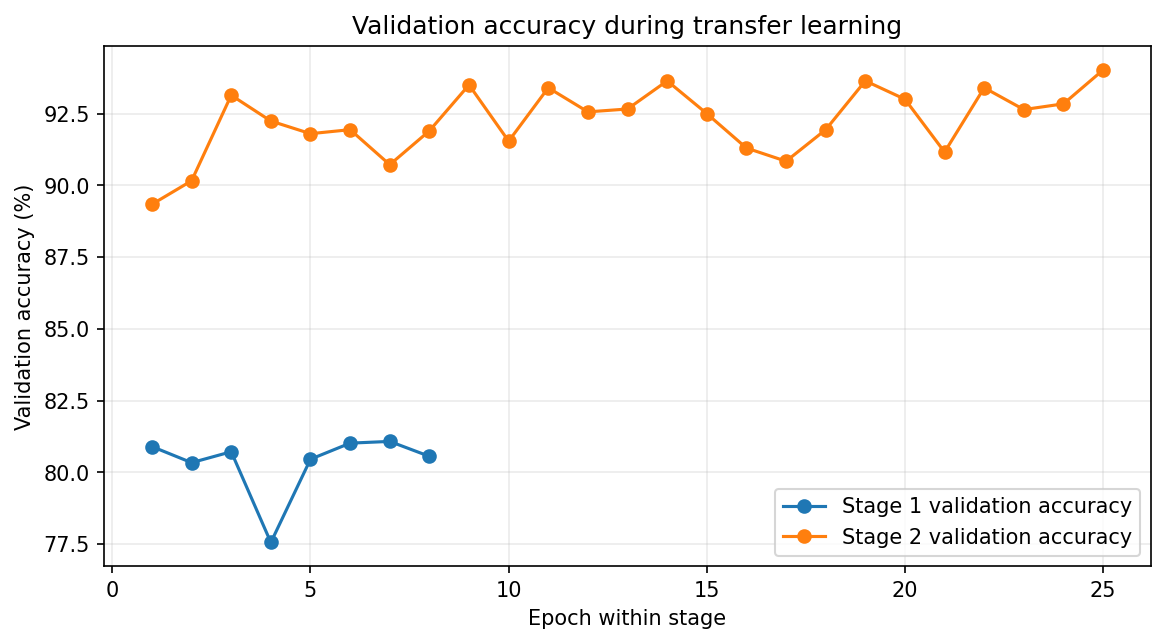

In [3]:
from io import BytesIO

import matplotlib.pyplot as plt

stage1 = load_csv("part1/part1_results/training_stage1_log.csv")
stage2 = load_csv("part1/part1_results/training_stage2_log.csv")

figure, axis = plt.subplots(figsize=(9, 4.5))
axis.plot(
    [int(row["epoch"]) + 1 for row in stage1],
    [float(row["val_accuracy"]) * 100 for row in stage1],
    marker="o",
    label="Stage 1 validation accuracy",
)
axis.plot(
    [int(row["epoch"]) + 1 for row in stage2],
    [float(row["val_accuracy"]) * 100 for row in stage2],
    marker="o",
    label="Stage 2 validation accuracy",
)
axis.set_xlabel("Epoch within stage")
axis.set_ylabel("Validation accuracy (%)")
axis.set_title("Validation accuracy during transfer learning")
axis.grid(alpha=0.25)
axis.legend()

buffer = BytesIO()
figure.savefig(buffer, format="png", bbox_inches="tight", dpi=150)
plt.close(figure)
display(Image(data=buffer.getvalue()))

## 3. Optimized model comparison

The comparison combines the baseline, architecture variants, and quantized TFLite models. Accuracy and latency were measured on the recorded host; quantized latency uses the TFLite CPU interpreter.

In [4]:
comparison_rows = load_csv("part2/part2_results/performance_comparison.csv")
table_rows = [
    [
        row["model"],
        row["backend"],
        f"{float(row['accuracy']) * 100:.2f}%",
        f"{float(row['accuracy_drop_pp']):.2f} pp",
        f"{float(row['model_size_mib']):.3f}",
        f"{float(row['single_latency_ms']):.3f}",
        row["input_resolution"],
    ]
    for row in comparison_rows
]
display(
    Markdown(
        markdown_table(
            ["Model", "Backend", "Accuracy", "Accuracy drop", "Size (MiB)", "Latency (ms)", "Input"],
            table_rows,
        )
    )
)

| Model | Backend | Accuracy | Accuracy drop | Size (MiB) | Latency (ms) | Input |
|---|---|---|---|---|---|---|
| baseline | Keras GPU | 93.71% | 0.00 pp | 26.008 | 2.497 | 224x224 |
| latency_optimized | Keras GPU | 89.34% | 4.37 pp | 8.484 | 2.456 | 160x160 |
| memory_optimized | Keras GPU | 84.43% | 9.28 pp | 3.239 | 2.451 | 160x160 |
| energy_optimized | Keras GPU | 87.46% | 6.25 pp | 8.502 | 2.284 | 160x160 |
| ptq_int8 | TFLite CPU | 87.84% | 5.87 pp | 0.937 | 0.663 | 160x160 |
| qat_int8 | TFLite CPU | 84.49% | 9.22 pp | 0.937 | 0.662 | 160x160 |
| mixed_precision | TFLite CPU | 89.26% | 4.45 pp | 1.369 | 0.535 | 160x160 |
| dynamic_range | TFLite CPU | 88.61% | 5.10 pp | 0.838 | 0.973 | 160x160 |

## 4. Pareto and batch-size trade-offs

The non-dominated models are calculated from accuracy, measured latency, and model size. The batch-size search illustrates the difference between per-request latency and aggregate throughput.

In [5]:
performance = load_json("part4/part4_results/performance_report.json")
pareto_rows = [
    ["Accuracy, latency, size", ", ".join(performance["pareto"]["accuracy_latency_size"])],
    ["Accuracy and latency", ", ".join(performance["pareto"]["accuracy_latency"])],
    ["Accuracy and size", ", ".join(performance["pareto"]["accuracy_model_size"])],
]
display(Markdown(markdown_table(["Objective set", "Non-dominated models"], pareto_rows)))

| Objective set | Non-dominated models |
|---|---|
| Accuracy, latency, size | baseline, latency_optimized, ptq_int8, qat_int8, mixed_precision, dynamic_range |
| Accuracy and latency | baseline, latency_optimized, mixed_precision |
| Accuracy and size | baseline, latency_optimized, mixed_precision, dynamic_range |

**Accuracy Vs Latency**

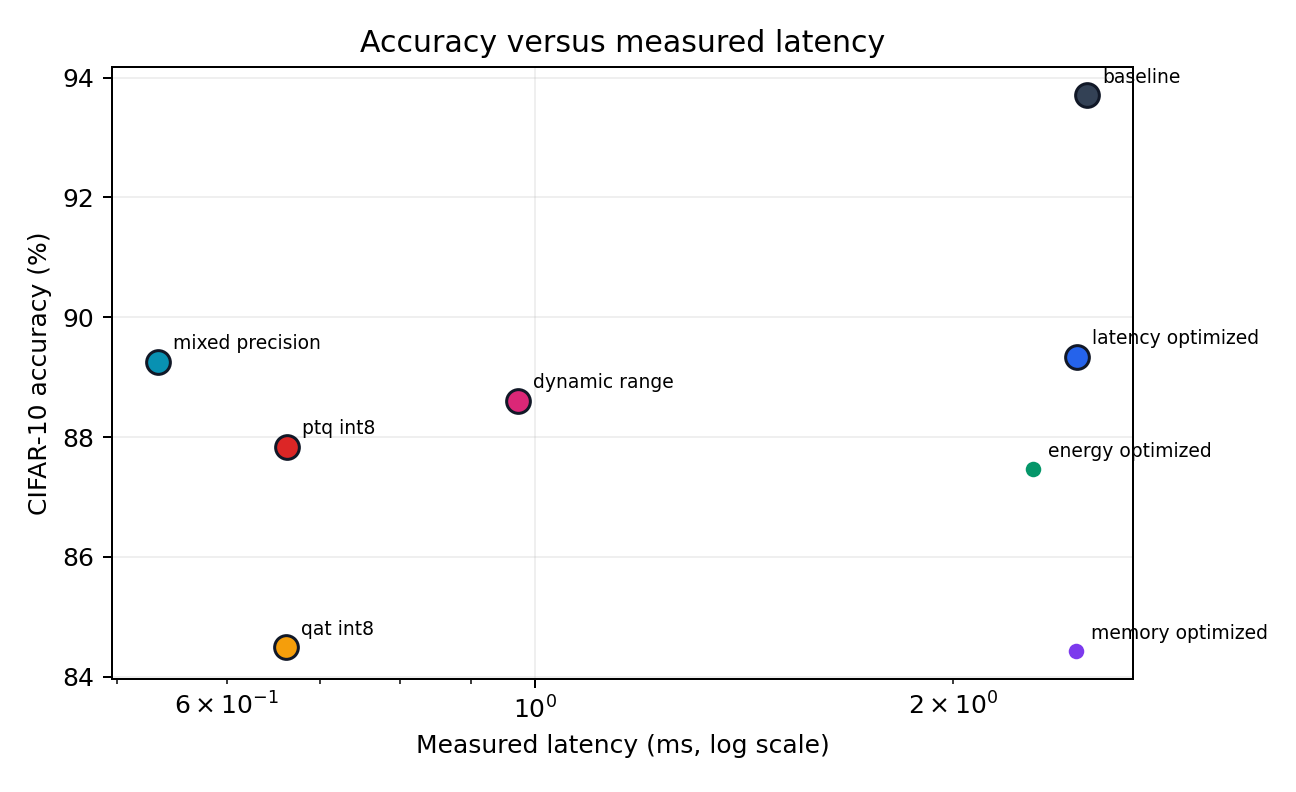

**Accuracy Vs Model Size**

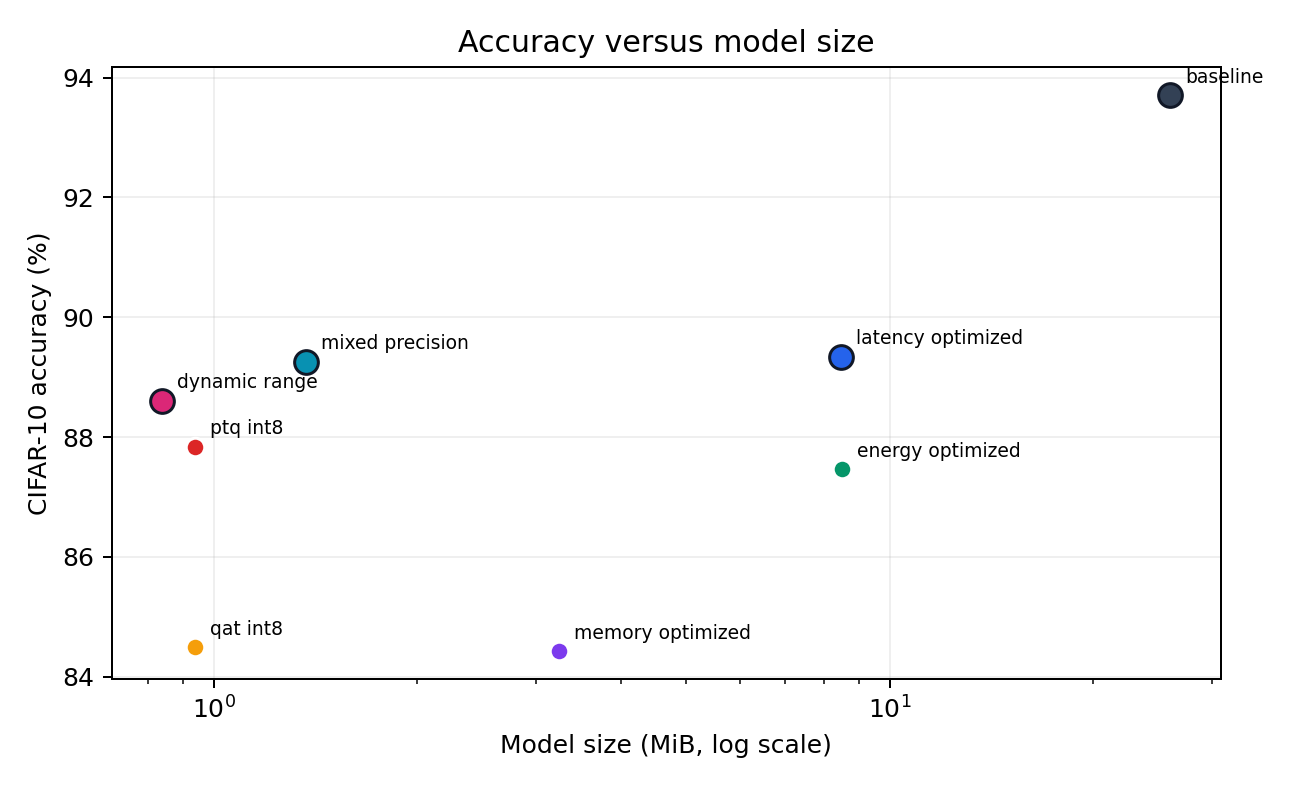

**Normalized Tradeoffs**

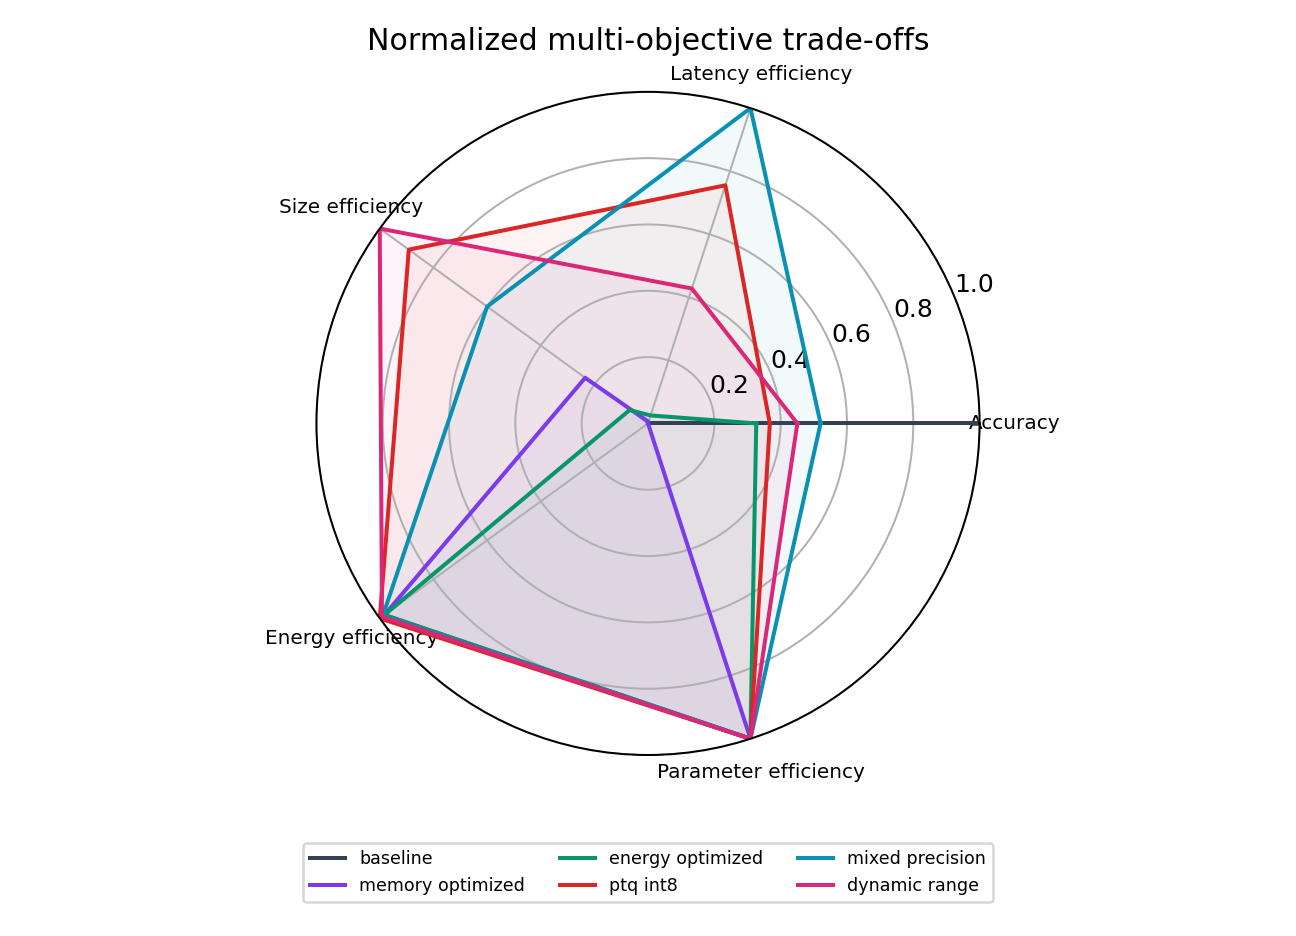

**Batch Scaling**

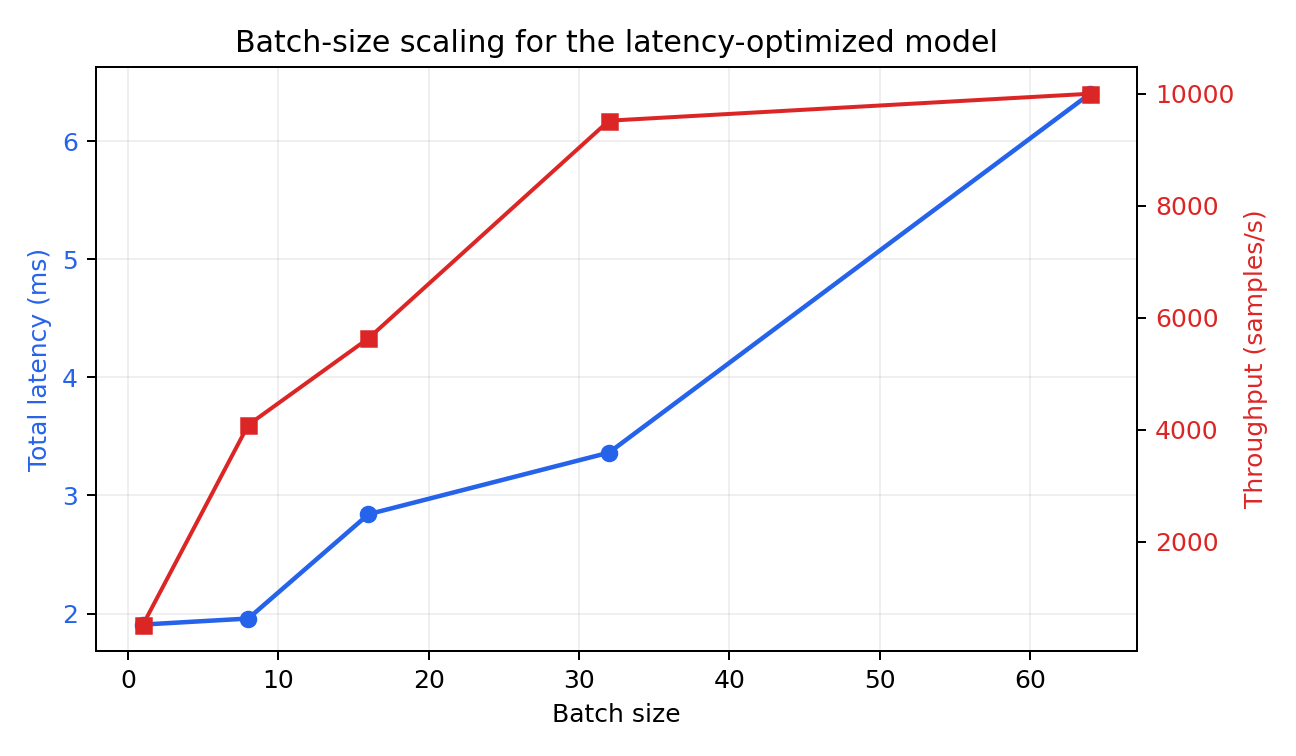

**Platform Effectiveness**

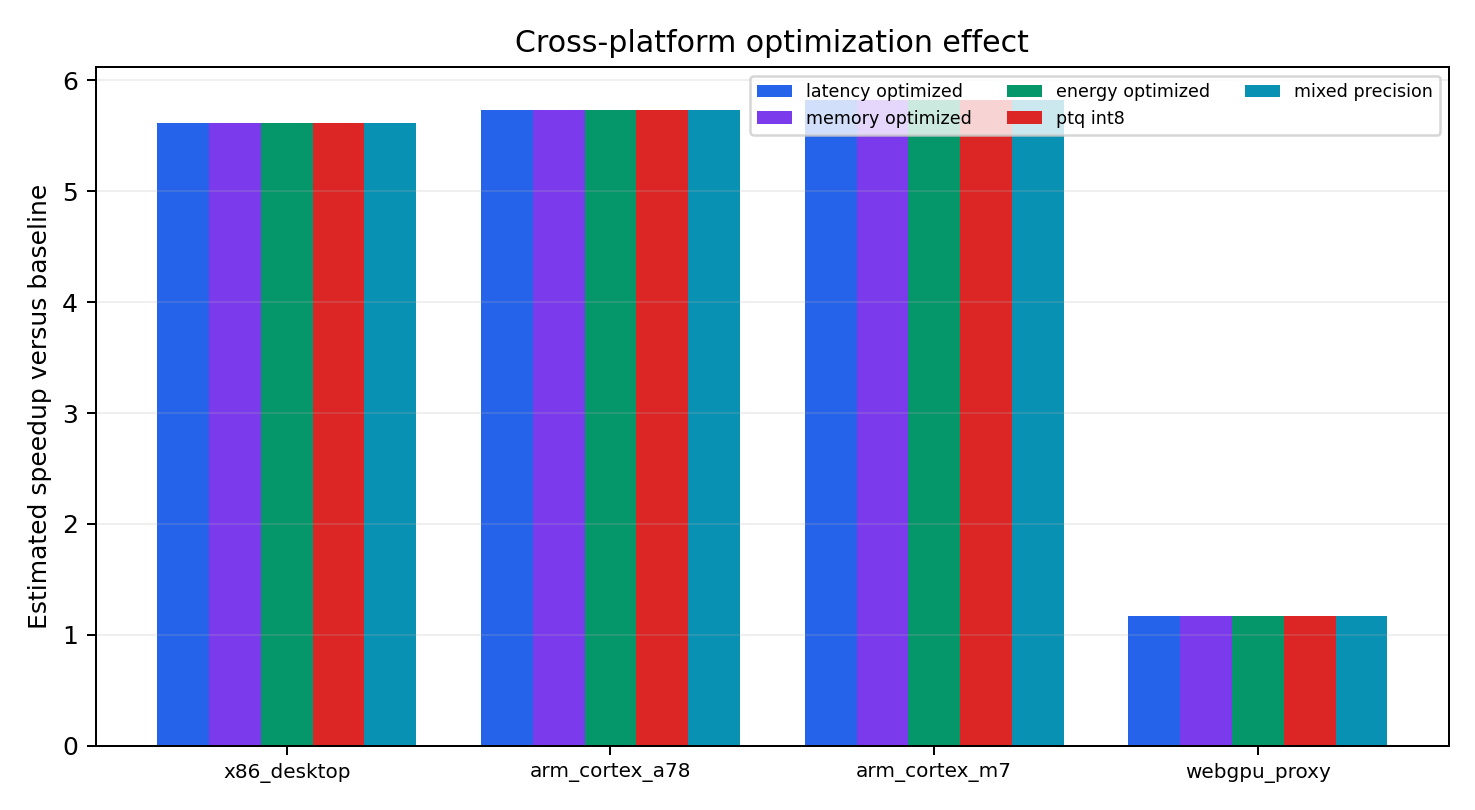

In [6]:
figure_dir = PROJECT_ROOT / "part4" / "part4_results" / "figures"
for filename in (
    "accuracy_vs_latency.png",
    "accuracy_vs_model_size.png",
    "normalized_tradeoffs.png",
    "batch_scaling.png",
    "platform_effectiveness.png",
):
    display(Markdown(f"**{filename.replace('_', ' ').removesuffix('.png').title()}**"))
    display(Image(filename=str(figure_dir / filename)))

## 5. Cross-platform validation

Measurements are kept separate from analytical estimates. The WebGPU result is a desktop proxy, while QEMU-CM is a simulated Cortex-M execution environment.

In [7]:
validation = load_json("part3/part3_results/simulation_validation.json")
qemu = validation["qemu_cm"]
webgpu = validation["webgpu_proxy"]

platform_rows = [
    ["[native-x86]", "PTQ INT8", f"{validation['native_x86']['measured_latency_ms']:.3f} ms", "Measured"],
    ["[QEMU-CM]", "PTQ INT8", f"{qemu['average_simulated_cpu_ms']:.3f} ms", "QEMU simulation"],
    ["[WebGPU-proxy]", "Latency optimized", f"{webgpu['mean_ms']:.3f} ms mean", "Desktop proxy"],
    ["[modeled-ARM]", "PTQ INT8", "355.319 ms", "Analytical estimate"],
]
display(
    Markdown(
        markdown_table(
            ["Context", "Model", "Latency", "Evidence"],
            platform_rows,
        )
    )
)

| Context | Model | Latency | Evidence |
|---|---|---|---|
| [native-x86] | PTQ INT8 | 0.663 ms | Measured |
| [QEMU-CM] | PTQ INT8 | 946.000 ms | QEMU simulation |
| [WebGPU-proxy] | Latency optimized | 4.907 ms mean | Desktop proxy |
| [modeled-ARM] | PTQ INT8 | 355.319 ms | Analytical estimate |

In [8]:
utilization = load_json("part4/part4_results/hardware_utilization.json")
mcu = utilization["mcu_memory_validity"]
mcu_rows = [
    ["Model bytes", f"{mcu['model_bytes']:,}"],
    ["Tensor-arena bytes", f"{mcu['tensor_arena_used_bytes']:,}"],
    ["Flash limit", f"{mcu['flash_limit_bytes']:,}"],
    ["SRAM limit", f"{mcu['sram_limit_bytes']:,}"],
    ["Fits flash", "Yes" if mcu["fits_flash"] else "No"],
    ["Fits SRAM", "Yes" if mcu["fits_sram"] else "No"],
]
display(Markdown(markdown_table(["Cortex-M metric", "Result"], mcu_rows)))

| Cortex-M metric | Result |
|---|---|
| Model bytes | 982,152 |
| Tensor-arena bytes | 707,028 |
| Flash limit | 2,097,152 |
| SRAM limit | 524,288 |
| Fits flash | Yes |
| Fits SRAM | No |

## 6. Interpretation

- The baseline preserves the highest accuracy but requires the most storage.
- Mixed FP16 gives the lowest measured host latency in this experiment.
- PTQ INT8 substantially reduces model size while retaining 87.84% accuracy.
- Cortex-M functional simulation succeeds, but the measured tensor arena exceeds the modeled 512 KiB SRAM budget.
- Energy and cache figures are analytical proxies, not physical measurements.
- Detailed tables are available in `performance_benchmarks.xlsx`; full written analysis is in `hardware_aware_analysis.md`.